# Assignment 3 - EDA: Multimodal Meme Sentiment (image + text)

Exploratory analysis consists: pair counts, missing-modality rates, text length, pair quality, label distribution,
image statistics, representative samples, and dataset limitations.

This notebook only **analyses** the data. It does not modify `data/raw/`, does not create the train/val/test split, and does not claim any model result. Run `scripts/audit_dataset.py` first (it produces `data/audit/samples.csv`).

In [86]:
from pathlib import Path
import difflib, textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd()
while ROOT.name != "assignment3" and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert ROOT.name == "assignment3", "Run from inside the assignment3 folder"

RAW = ROOT / "data/raw/memotion"
IMAGE_ROOT = RAW / "images/images"
AUDIT = ROOT / "data/audit/samples.csv"
FIG_DIR = ROOT.parent / "assets/eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)

LABELS = ["very_negative", "negative", "neutral", "positive", "very_positive"]
SEED = 42
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def savefig(name):
    path = FIG_DIR / f"assignment3-{name}.png"
    plt.savefig(path, bbox_inches="tight")
    print("saved", path.relative_to(ROOT.parent))

## 1. Load data

In [87]:
labels = pd.read_csv(RAW / "labels.csv", encoding="utf-8-sig", index_col=0, keep_default_na=False)
audit = pd.read_csv(AUDIT, encoding="utf-8-sig", keep_default_na=False)
for c in ["image_exists", "decode_ok", "corrected_text_blank", "ocr_text_blank", "eligible"]:
    audit[c] = audit[c].astype(str).eq("True")

assert len(labels) == len(audit) and (labels["image_name"].values == audit["image_name"].values).all()
df = labels.merge(audit.drop(columns=["label"]), on="image_name", validate="one_to_one")
df = df.rename(columns={"overall_sentiment": "label"})
df["label"] = pd.Categorical(df["label"], categories=LABELS, ordered=True)
print("columns:", list(labels.columns))
print("rows:", len(df), "| unknown labels:", df["label"].isna().sum())
df.head(3)

columns: ['image_name', 'text_ocr', 'text_corrected', 'overall_sentiment']
rows: 6992 | unknown labels: 0


,image_name,text_ocr,text_corrected,label,image_exists,decode_ok,width,height,mode,error,corrected_text_blank,ocr_text_blank,corrected_word_count,eligible,exclusion_reason,file_sha256,pixel_sha256
0,image_1.jpg,LOOK THERE MY FRIEND LIGHTYEAR NOW ALL SOHALIKUT TREND PLAY THE 10 YEARS CHALLENGE AT FACEBOOK imgflip.com,LOOK THERE MY FRIEND LIGHTYEAR NOW ALL SOHALIKUT TREND PLAY THE 10 YEARS CHALLENGE AT FACEBOOK imgflip.com,very_positive,True,True,735,500,RGB,,False,False,17,True,,c62a010d1d4f1855047d950a16eccc6be5543850162c0e72232bbbbb35c1d48d,764baf70ee2cb0f814f4e09bed6fdc5fb5b1a21edb5b7e23cdb8d6714f10b62b
1,image_2.jpeg,The best of #10 YearChallenge! Completed in less the 4 years. Kudus to @narendramodi ji 8:05 PM - 16 Jan 2019 from Mumbai,The best of #10 YearChallenge! Completed in less the 4 years. Kudus to @narendramodi ji 8:05 PM - 16 Jan 2019 from Mumbai India,very_positive,True,True,749,506,RGB,,False,False,24,True,,02f0395b06dfd2ec0bbe34a11637154111c210bbef991315b49758deb80b0d8f,c56435855fb72ae7ea083d27d85e2c1e18cb9424460da1e6fcb5d1bdbddf4bbf
2,image_3.JPG,Sam Thorne @Strippin ( Follow Follow Saw everyone posting these 2009 vs 2019 pics so here's mine 6:23 PM - 12 Jan 2019 O 636 Retweets 3,Sam Thorne @Strippin ( Follow Follow Saw everyone posting these 2009 vs 2019 pics so here's mine 6:23 PM - 12 Jan 2019 O 636 Retweets 3 224 LIKES 65 636 3.2K,positive,True,True,766,571,RGB,,False,False,32,True,,ac3729243149da81b00fc2c1f1646f9f60b59c9770c893c8ac5db0336b8c247a,0591b4a4b3558469e69bb37b4a2ecd9bd7ce0139f9d9925b2f77db8ff1b0b2f5


## 2. Pair counts and missing-modality rates

In [88]:
n = len(df)
summary = pd.Series({
    "CSV rows (raw pairs)": n,
    "Unique image names": df["image_name"].nunique(),
    "Image file missing": (~df["image_exists"]).sum(),
    "Image decode failed": (df["image_exists"] & ~df["decode_ok"]).sum(),
    "Corrected text blank": df["corrected_text_blank"].sum(),
    "OCR text blank": df["ocr_text_blank"].sum(),
    "Eligible pairs (before duplicate review)": df["eligible"].sum(),
})
table = summary.to_frame("count")
table["% of raw"] = (table["count"] / n * 100).round(2)
display(table)
print("\nExclusion reasons:")
display(df.loc[~df["eligible"], ["image_name", "label", "exclusion_reason", "error"]])

,count,% of raw
CSV rows (raw pairs),6992,100.00
Unique image names,6992,100.00
Image file missing,0,0.00
Image decode failed,1,0.01
Corrected text blank,5,0.07
OCR text blank,161,2.30
Eligible pairs (before duplicate review),6986,99.91



Exclusion reasons:


,image_name,label,exclusion_reason,error
119,image_120.jpg,positive,blank_corrected_text,
4799,image_4800.jpg,neutral,blank_corrected_text,
5118,image_5119.png,positive,image_decode_failed,OSError: image file is truncated
6781,image_6782.jpg,positive,blank_corrected_text,
6784,image_6785.jpg,positive,blank_corrected_text,
6786,image_6787.jpg,positive,blank_corrected_text,


## 3. Label distribution

,count,percent
label,,
very_negative,151,2.16
negative,480,6.86
neutral,2201,31.48
positive,3127,44.72
very_positive,1033,14.77


Imbalance ratio (max/min): 20.71
Majority-class baseline accuracy: 0.447
saved assets\eda\assignment3-class-distribution.png


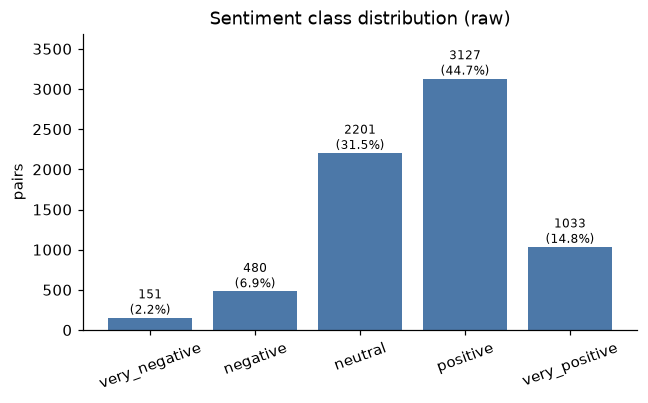

In [89]:
cnt = df["label"].value_counts().reindex(LABELS)
dist = pd.DataFrame({"count": cnt, "percent": (cnt / n * 100).round(2)})
display(dist)
print(f"Imbalance ratio (max/min): {cnt.max() / cnt.min():.2f}")
print(f"Majority-class baseline accuracy: {cnt.max() / n:.3f}")

fig, ax = plt.subplots(figsize=(6.5, 3.5))
bars = ax.bar(LABELS, cnt.values, color="#4C78A8")
ax.bar_label(bars, labels=[f"{v}\n({v/n*100:.1f}%)" for v in cnt.values], fontsize=8)
ax.set_ylabel("pairs"); ax.set_title("Sentiment class distribution (raw)")
ax.set_ylim(0, cnt.max() * 1.18); plt.xticks(rotation=20)
savefig("class-distribution"); plt.show()

## 4. Text statistics

,words,chars,ocr_words
count,6987.0,6987.0,6987.0
mean,14.7,82.7,13.1
std,9.0,50.4,8.9
min,1.0,2.0,0.0
50%,13.0,72.0,11.0
90%,26.0,142.4,24.0
95%,31.0,173.0,29.0
99%,43.0,252.3,41.0
max,189.0,1026.0,189.0


saved assets\eda\assignment3-text-length.png


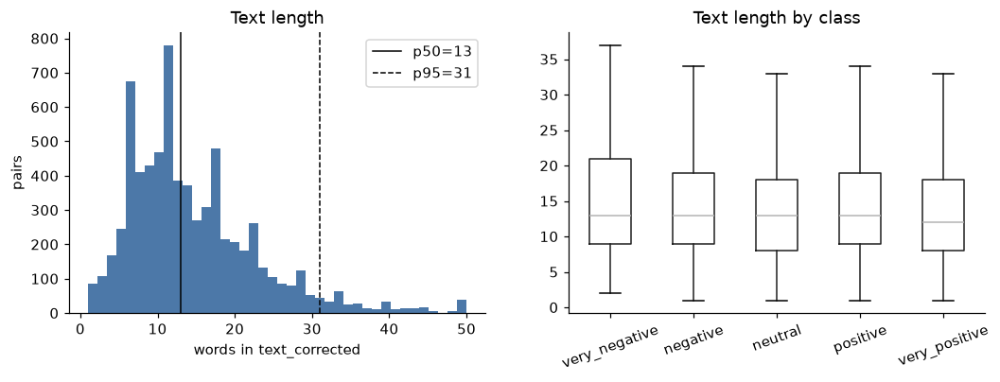

Very short (<=2 words): 86 | very long (>100 words): 1
Suggested max_len covering 95% of texts (words): 31


In [90]:
df["words"] = df["text_corrected"].str.split().str.len()
df["chars"] = df["text_corrected"].str.len()
df["ocr_words"] = df["text_ocr"].str.split().str.len()
ok = df[~df["corrected_text_blank"]]
display(ok[["words", "chars", "ocr_words"]].describe(percentiles=[.5, .9, .95, .99]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(ok["words"].clip(upper=ok["words"].quantile(.995)), bins=40, color="#4C78A8")
for q, ls in [(.5, "-"), (.95, "--")]:
    v = ok["words"].quantile(q); axes[0].axvline(v, color="k", ls=ls, lw=1, label=f"p{int(q*100)}={v:.0f}")
axes[0].set_xlabel("words in text_corrected"); axes[0].set_ylabel("pairs")
axes[0].set_title("Text length"); axes[0].legend()
ok.boxplot(column="words", by="label", ax=axes[1], grid=False, showfliers=False)
axes[1].set_title("Text length by class"); axes[1].set_xlabel(""); plt.suptitle("")
plt.setp(axes[1].get_xticklabels(), rotation=20)
savefig("text-length"); plt.show()

print("Very short (<=2 words):", (ok["words"] <= 2).sum(), "| very long (>100 words):", (ok["words"] > 100).sum())
print("Suggested max_len covering 95% of texts (words):", int(ok["words"].quantile(.95)))

## 5. Image statistics

,w,h,aspect,kb
count,6991.00,6991.00,6991.00,6991.00
mean,587.03,546.47,1.14,102.90
std,256.84,250.04,0.36,169.53
min,100.00,123.00,0.33,4.69
5%,270.00,248.50,0.66,17.03
50%,500.00,500.00,1.01,66.22
95%,1024.00,960.00,1.79,286.51
max,4961.00,5553.00,4.35,8200.70


Color modes: {'RGB': 5467, 'P': 1248, 'RGBA': 243, 'L': 31, 'CMYK': 2}
File extensions: {'jpg': 4965, 'png': 1678, 'jpeg': 345, 'bmp': 2, 'jpe': 1}
Total image size: 702.5 MB
Distinct (w,h) pairs: 4224
saved assets\eda\assignment3-image-sizes.png


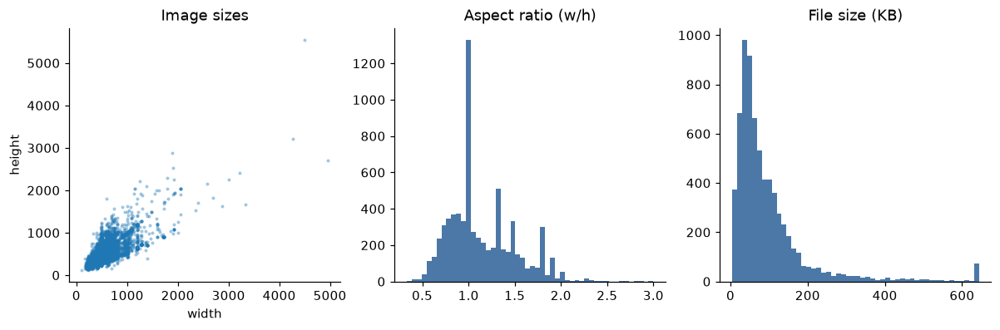

In [91]:
im = df[df["decode_ok"]].copy()
im["w"] = im["width"].astype(int); im["h"] = im["height"].astype(int)
im["aspect"] = im["w"] / im["h"]
im["ext"] = im["image_name"].str.extract(r"\.([^.]+)$")[0].str.lower()
im["kb"] = [(IMAGE_ROOT / f).stat().st_size / 1024 for f in im["image_name"]]
display(im[["w", "h", "aspect", "kb"]].describe(percentiles=[.05, .5, .95]).round(2))
print("Color modes:", im["mode"].value_counts().to_dict())
print("File extensions:", im["ext"].value_counts().to_dict())
print("Total image size: %.1f MB" % (im["kb"].sum() / 1024))
print("Distinct (w,h) pairs:", im[["w", "h"]].drop_duplicates().shape[0])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].scatter(im["w"], im["h"], s=3, alpha=.3); axes[0].set_xlabel("width"); axes[0].set_ylabel("height")
axes[0].set_title("Image sizes")
axes[1].hist(im["aspect"].clip(upper=3), bins=50, color="#4C78A8"); axes[1].set_title("Aspect ratio (w/h)")
axes[2].hist(im["kb"].clip(upper=im["kb"].quantile(.99)), bins=50, color="#4C78A8"); axes[2].set_title("File size (KB)")
savefig("image-sizes"); plt.show()

## 6. Pair quality

Checks: (a) OCR vs. corrected text agreement, (b) exact duplicate images
(by decoded-pixel hash), (c) duplicate texts across different images
(template / near-duplicate candidates), (d) label conflicts inside duplicate groups.
These groups drive the **grouped split** later: every group must stay in one partition.

OCR text identical to corrected: 67.9%
Similarity < 0.8 (heavily corrected): 969 pairs
OCR blank but corrected present: 157
saved assets\eda\assignment3-ocr-agreement.png


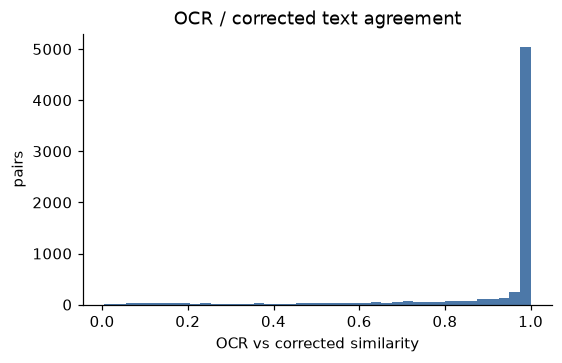

In [92]:
both = df[~df["corrected_text_blank"] & ~df["ocr_text_blank"]].copy()
both["same"] = both["text_ocr"].str.strip() == both["text_corrected"].str.strip()
both["sim"] = [difflib.SequenceMatcher(None, a.lower(), b.lower()).ratio()
               for a, b in zip(both["text_ocr"], both["text_corrected"])]
print(f"OCR text identical to corrected: {both['same'].mean()*100:.1f}%")
print(f"Similarity < 0.8 (heavily corrected): {(both['sim'] < 0.8).sum()} pairs")
print(f"OCR blank but corrected present: {(df['ocr_text_blank'] & ~df['corrected_text_blank']).sum()}")

fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.hist(both["sim"], bins=40, color="#4C78A8"); ax.set_xlabel("OCR vs corrected similarity"); ax.set_ylabel("pairs")
ax.set_title("OCR / corrected text agreement"); savefig("ocr-agreement"); plt.show()

In [93]:
dec = df[df["decode_ok"]].copy()

# (b) exact duplicate images
g = dec.groupby("pixel_sha256")
dec["img_group_size"] = g["image_name"].transform("size")
dup_img = dec[dec["img_group_size"] > 1]
grp_labels = dup_img.groupby("pixel_sha256")["label"].nunique()
print(f"Exact duplicate image groups: {dup_img['pixel_sha256'].nunique()} "
      f"({len(dup_img)} images, {len(dup_img) - dup_img['pixel_sha256'].nunique()} redundant copies)")
print(f"  groups with conflicting labels: {(grp_labels > 1).sum()}")
print(f"  groups with identical corrected text: "
      f"{(dup_img.groupby('pixel_sha256')['text_corrected'].nunique() == 1).sum()}")

# (c) duplicate texts across different images
norm = dec["text_corrected"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
dec["text_norm"] = norm
tx = dec[~dec["corrected_text_blank"]].groupby("text_norm")
dec["txt_group_size"] = tx["image_name"].transform("size")
dup_txt = dec[(dec["txt_group_size"] > 1) & ~dec["corrected_text_blank"]]
print(f"\nDuplicate-text groups (different files, same text): {dup_txt['text_norm'].nunique()} "
      f"({len(dup_txt)} images)")
print("Most repeated texts:")
display(dup_txt["text_norm"].value_counts().head(8).to_frame("images").assign(
    text=lambda d: [t[:70] for t in d.index]).reset_index(drop=True))

# (e) junk / non-caption text (scraping or OCR artifacts)
junk = dec["text_corrected"].str.strip().str.lower().str.match(r"^(#name\?|<html|<!doctype|<\?xml)|^[^a-z0-9]*$")
print(f"\nJunk/non-caption texts (e.g. '#name?', HTML dumps, no alphanumerics): {junk.sum()}")
display(dec.loc[junk, ["image_name", "label", "text_corrected"]].assign(
    text_corrected=lambda d: d["text_corrected"].str.slice(0, 60)).head(12))

# Lower bound on the number of leakage-prone images
affected = dec[(dec["img_group_size"] > 1) | (dec["txt_group_size"] > 1)]
print(f"\nImages in some duplicate/template candidate group: {len(affected)} "
      f"({len(affected)/len(dec)*100:.1f}% of decodable images)")

Exact duplicate image groups: 25 (51 images, 26 redundant copies)
  groups with conflicting labels: 16
  groups with identical corrected text: 16

Duplicate-text groups (different files, same text): 46 (101 images)
Most repeated texts:


,images,text
0,5,#name?
1,5,"<html><head><meta content=""text/html; charset=utf-8"" http-equiv=""conte"
2,3,bill is on the internet. bill sees something that offends him. bill mo
3,3,feminism. you keep using that word i do not think it means what you th
4,3,but i'm such a nice guy memegenerator.net
5,2,language! (..really? ig blerd.vision ...did we just become best friend
6,2,nose bleed??? judge! slow play! quickmeme.com
7,2,no new baby godfather memes dies memegenerator.net



Junk/non-caption texts (e.g. '#name?', HTML dumps, no alphanumerics): 15


,image_name,label,text_corrected
119,image_120.jpg,positive,
1769,image_1770.jpg,neutral,#NAME?
1919,image_1920.png,positive,"<html><head><meta content=""text/html; charset=UTF-8"" http-eq"
2176,image_2177.png,neutral,"<html><head><meta content=""text/html; charset=UTF-8"" http-eq"
2466,image_2467.jpg,neutral,#NAME?
4799,image_4800.jpg,neutral,
4804,image_4805.png,positive,"<html><head><meta content=""text/html; charset=UTF-8"" http-eq"
4995,image_4996.jpg,neutral,#NAME?
5249,image_5250.jpg,positive,"<html><head><meta content=""text/html; charset=UTF-8"" http-eq"
5485,image_5486.png,neutral,"<html><head><meta content=""text/html; charset=UTF-8"" http-eq"



Images in some duplicate/template candidate group: 119 (1.7% of decodable images)


review rows: 51 | groups: 25 | label conflicts: 16 | decisions filled: 0
Matches the pixel-hash groups computed above: True
saved assets\eda\assignment3-duplicate-examples.png


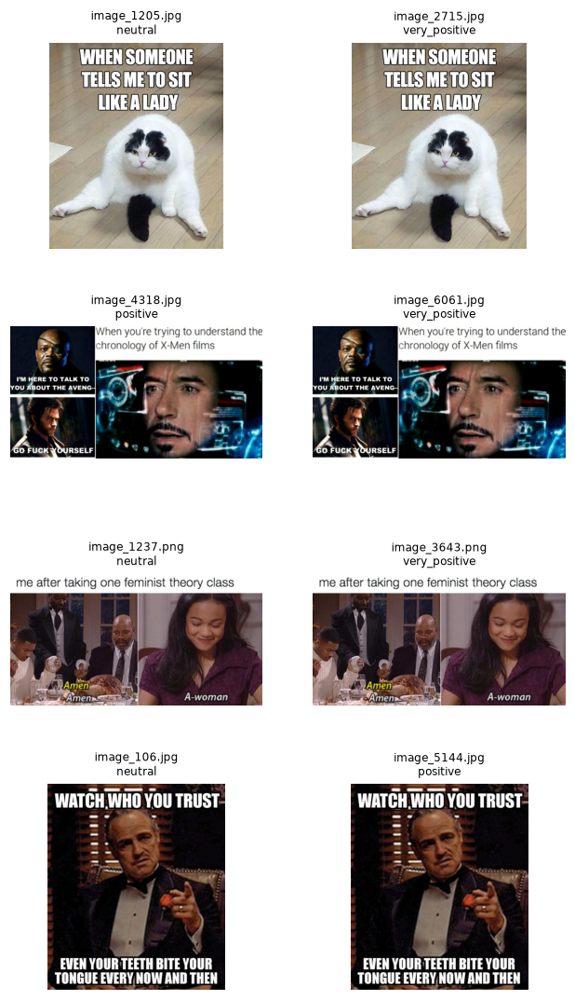

In [94]:
# Existing manual-review file (if present)
rev = ROOT / "data/review/exact_duplicates.csv"
if rev.exists():
    r = pd.read_csv(rev, encoding="utf-8-sig", keep_default_na=False)
    print("review rows:", len(r), "| groups:", r["group_id"].nunique(),
          "| label conflicts:", r.groupby("group_id")["label_conflict"].first().astype(str).eq("True").sum(),
          "| decisions filled:", r["decision"].ne("").sum())
    print("Matches the pixel-hash groups computed above:",
          set(r["group_id"]) == set(dup_img["pixel_sha256"]))

# Examples of duplicate images
show = dup_img.sort_values(["pixel_sha256", "image_name"]).groupby("pixel_sha256").head(2)
keys = show["pixel_sha256"].drop_duplicates().head(4)
fig, axes = plt.subplots(len(keys), 2, figsize=(7, 3 * len(keys)))
axes = np.atleast_2d(axes)
for i, k in enumerate(keys):
    for j, (_, row) in enumerate(show[show["pixel_sha256"] == k].iterrows()):
        axes[i, j].imshow(Image.open(IMAGE_ROOT / row["image_name"]).convert("RGB"))
        axes[i, j].set_title(f"{row['image_name']}\n{row['label']}", fontsize=8); axes[i, j].axis("off")
savefig("duplicate-examples"); plt.show()

### Full listing of duplicates (image / text / label)

**Legend of duplicate cases** ("same image" = identical decoded pixels, i.e. same `pixel_sha256`; "same text" = identical `text_corrected` after lowercasing and whitespace normalisation):

| Code | Case | Meaning |
|---|---|---|
| A1 | Same image, same text, same label | Pure redundant copies (harmless, but must stay in one split) |
| A2 | Same image, different text, same label | Same picture with a different caption/OCR; label is consistent |
| A3 | Same image, same text, different label | Identical input with conflicting labels (label noise) |
| A4 | Same image, different text, different label | Same picture with different captions and conflicting labels |
| B1 | Same text, different image, same label | Same caption on different images (template reuse); label is consistent |
| B2 | Same text, different image, different label | Same caption on different images with conflicting labels (label noise) |

Groups are exported to `assets/eda/duplicates/<code>/`.

In [95]:
# Print ALL duplicate cases in full (no truncation)
pd.set_option("display.max_rows", None, "display.max_colwidth", None, "display.width", 250)
d = dec.copy()
d["text_norm"] = d["text_corrected"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()

def show_groups(title, groups):
    print("=" * 100); print(f"{title}: {len(groups)} group(s)"); print("=" * 100)
    for k, g in groups:
        print(f"\n--- group {str(k)[:12]} ({len(g)} images) ---")
        print(g[["image_name", "label", "text_corrected"]].to_string(index=False))

# A. Same image (pixel hash)
img_g = [(k, g) for k, g in d.groupby("pixel_sha256") if len(g) > 1]
A1 = [(k, g) for k, g in img_g if g["label"].nunique() == 1 and g["text_norm"].nunique() == 1]
A2 = [(k, g) for k, g in img_g if g["label"].nunique() == 1 and g["text_norm"].nunique() > 1]
A3 = [(k, g) for k, g in img_g if g["label"].nunique() > 1 and g["text_norm"].nunique() == 1]
A4 = [(k, g) for k, g in img_g if g["label"].nunique() > 1 and g["text_norm"].nunique() > 1]
show_groups("A1. Same image, same text, same label", A1)
show_groups("A2. Same image, DIFFERENT text, same label", A2)
show_groups("A3. Same image, same text, DIFFERENT label", A3)
show_groups("A4. Same image, DIFFERENT text, DIFFERENT label", A4)

# B. Same text, different image files
t = d[~d["corrected_text_blank"]]
txt_g = [(k, g) for k, g in t.groupby("text_norm") if len(g) > 1 and g["pixel_sha256"].nunique() > 1]
B1 = [(k, g) for k, g in txt_g if g["label"].nunique() == 1]
B2 = [(k, g) for k, g in txt_g if g["label"].nunique() > 1]
show_groups("B1. Same text, DIFFERENT image, same label", B1)
show_groups("B2. Same text, DIFFERENT image, DIFFERENT label", B2)

print("\nSUMMARY:", {n: len(x) for n, x in dict(A1=A1, A2=A2, A3=A3, A4=A4, B1=B1, B2=B2).items()})


A1. Same image, same text, same label: 6 group(s)

--- group 44b82297fad4 (2 images) ---
    image_name    label                                         text_corrected
 image_101.jpg positive YOU PUT THAT FAT BASTARD ON THE HIT LIST WITH PLEASURE
image_6366.jpg positive YOU PUT THAT FAT BASTARD ON THE HIT LIST WITH PLEASURE

--- group a7f9d30c82dd (2 images) ---
     image_name    label                              text_corrected
image_1624.jpeg positive CONTRACT ON ME FROM BABY GODFATHER SURVIVED
image_4937.jpeg positive CONTRACT ON ME FROM BABY GODFATHER SURVIVED

--- group c3e43b6be6fb (2 images) ---
    image_name    label                                              text_corrected
image_3360.png positive AFRICAN LION LYIN' AFRICAN It's not racist  it's the TRUTH!
image_4557.png positive AFRICAN LION LYIN' AFRICAN It's not racist  it's the TRUTH!

--- group da03950e73c3 (2 images) ---
    image_name    label                                text_corrected
  image_88.jpg positive NOSE

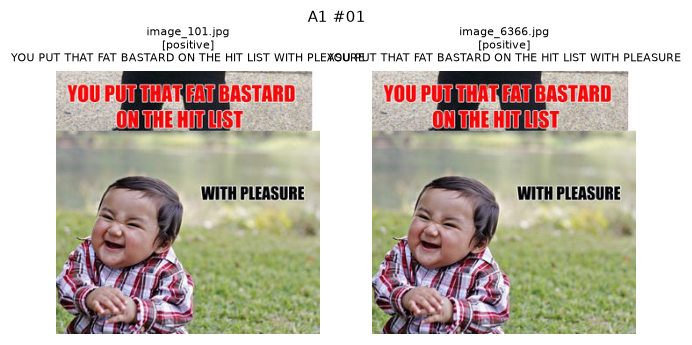

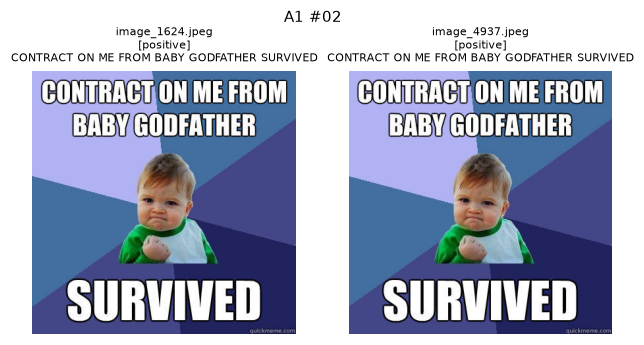

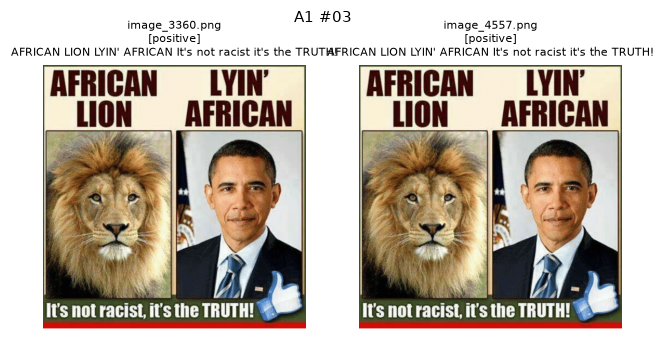

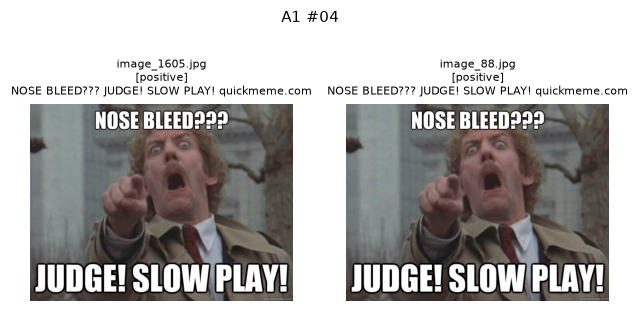

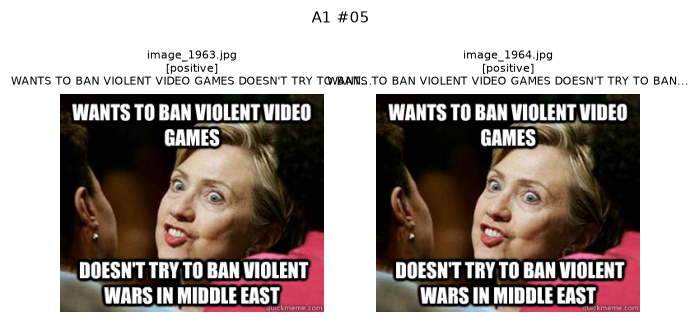

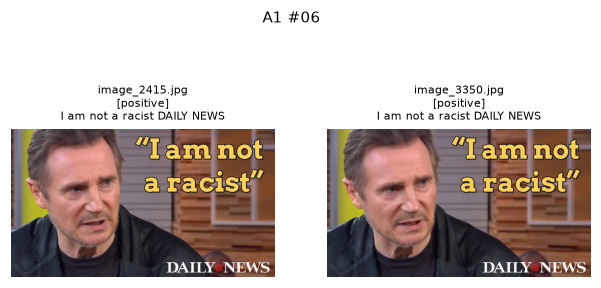

A1 6 images saved -> assets\eda\duplicates\A1


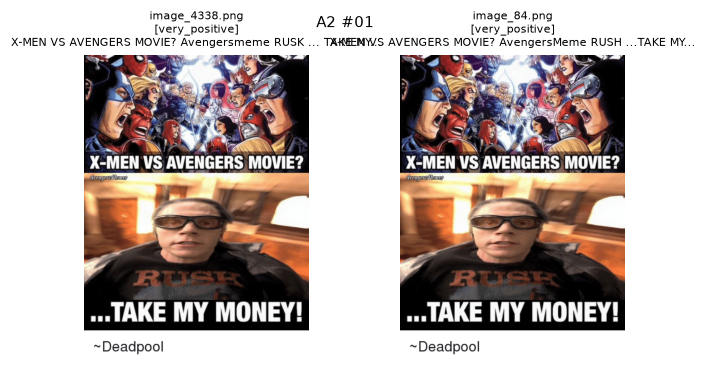

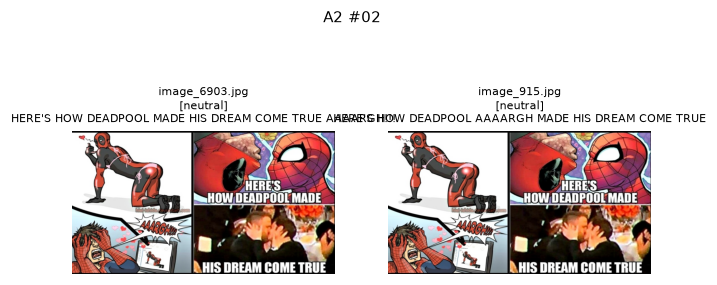

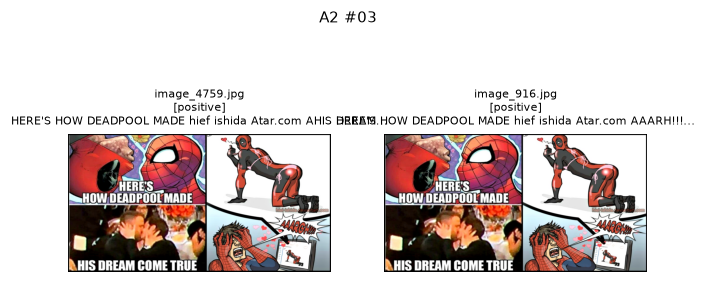

A2 3 images saved -> assets\eda\duplicates\A2


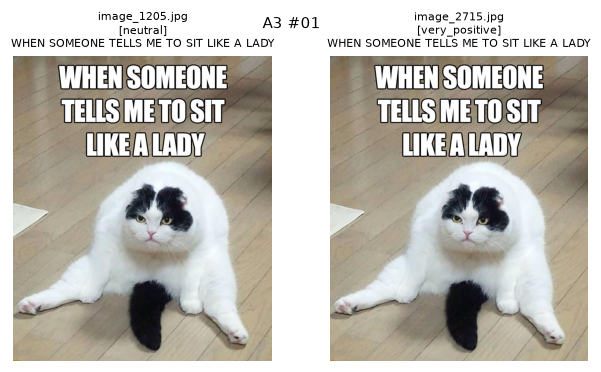

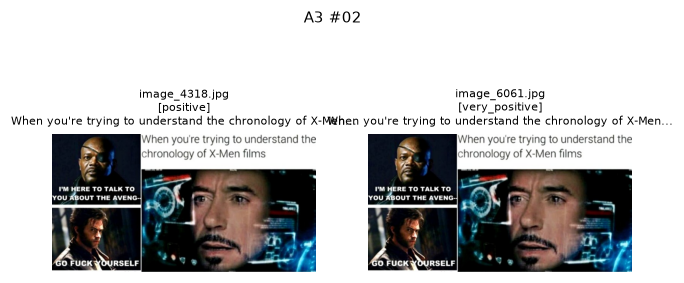

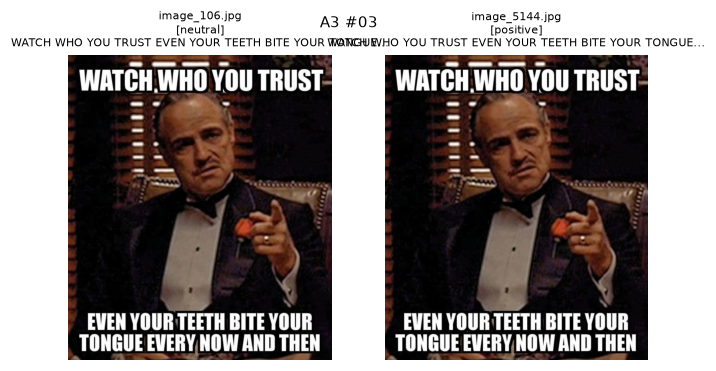

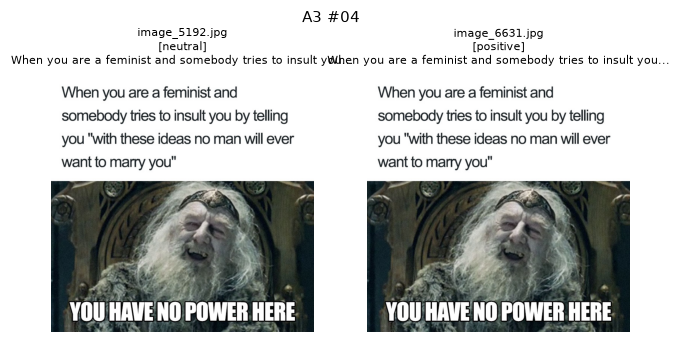

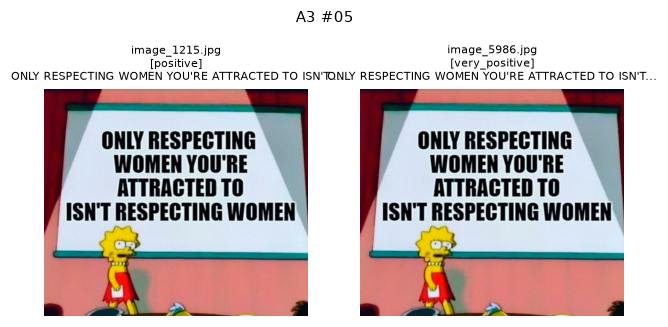

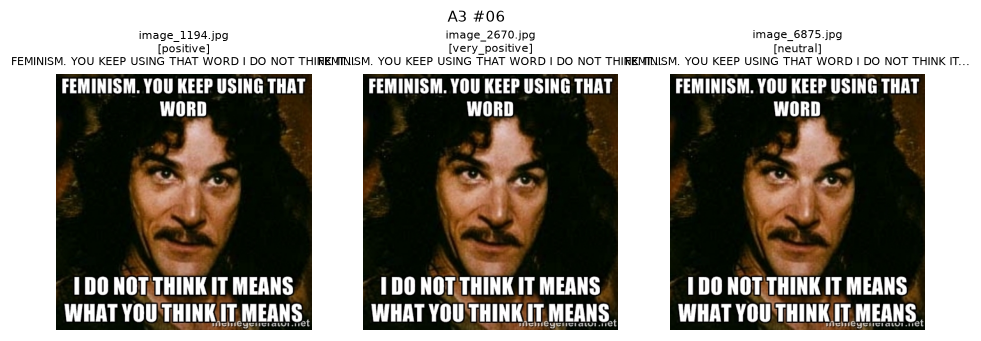

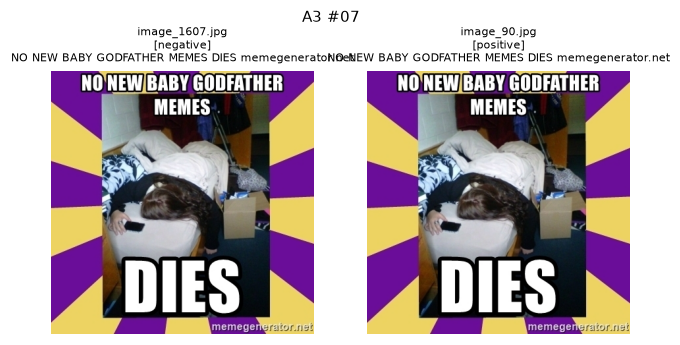

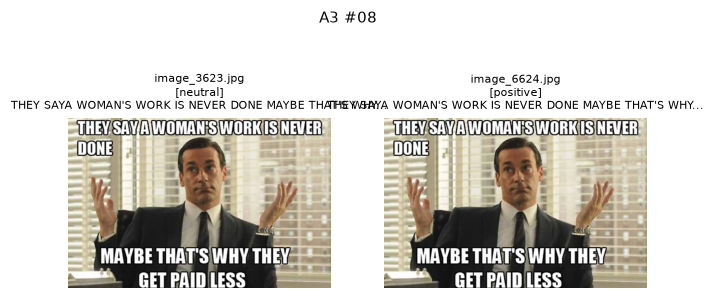

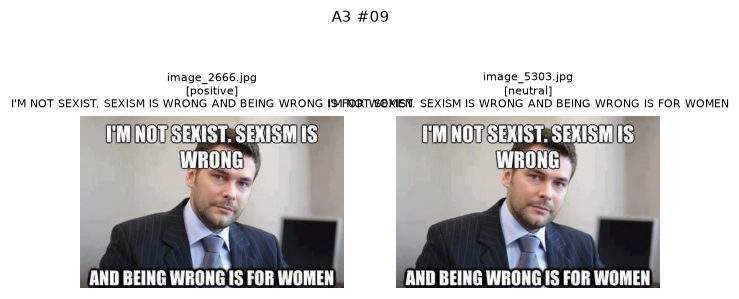

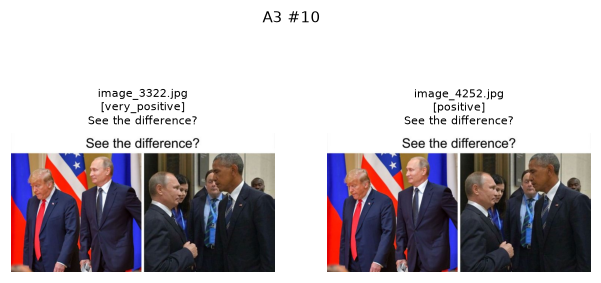

A3 10 images saved -> assets\eda\duplicates\A3


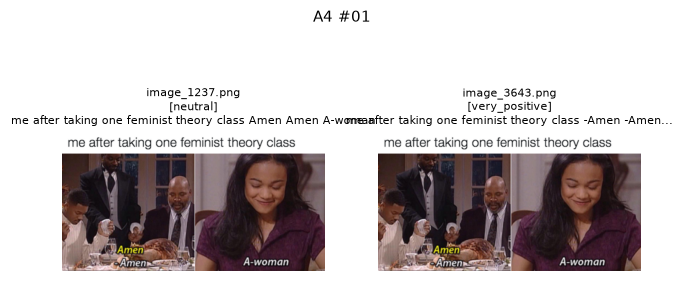

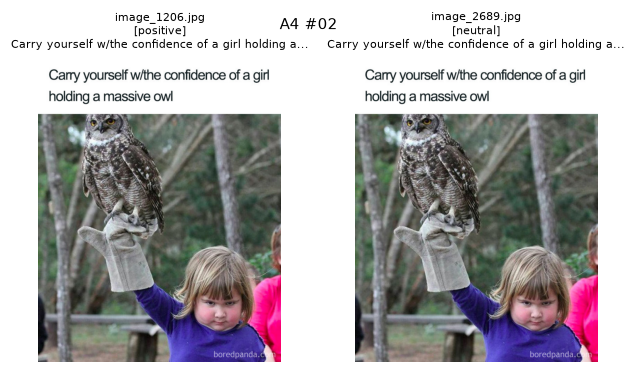

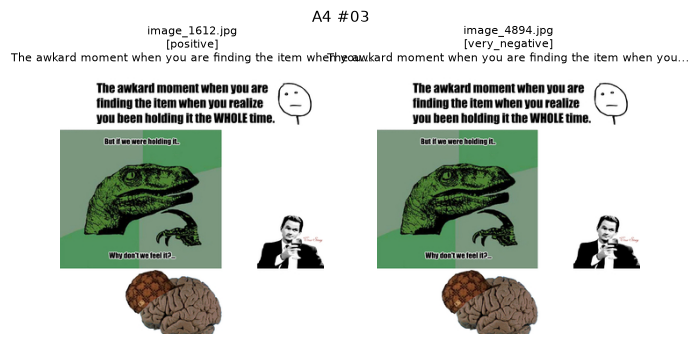

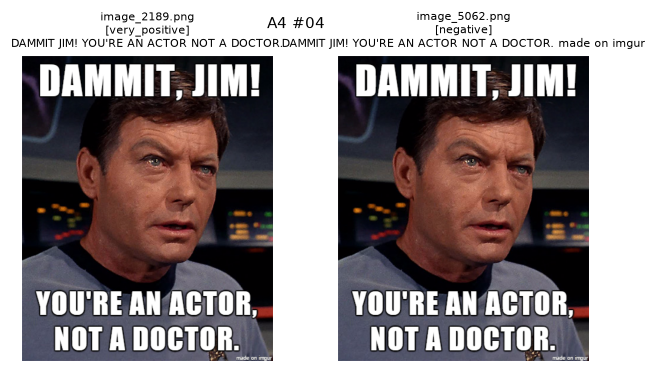

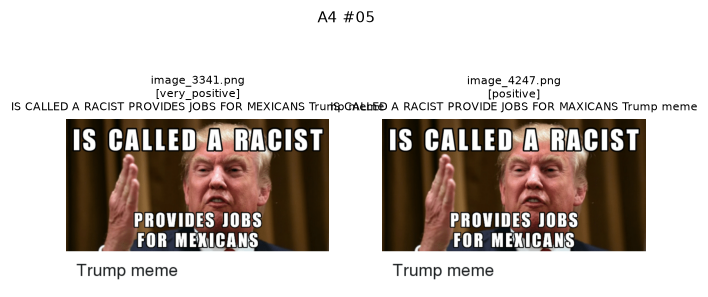

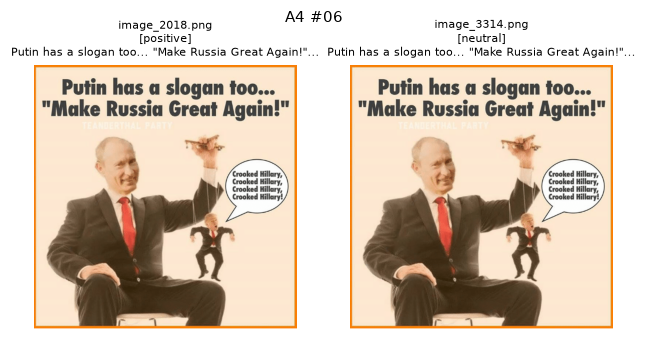

A4 6 images saved -> assets\eda\duplicates\A4


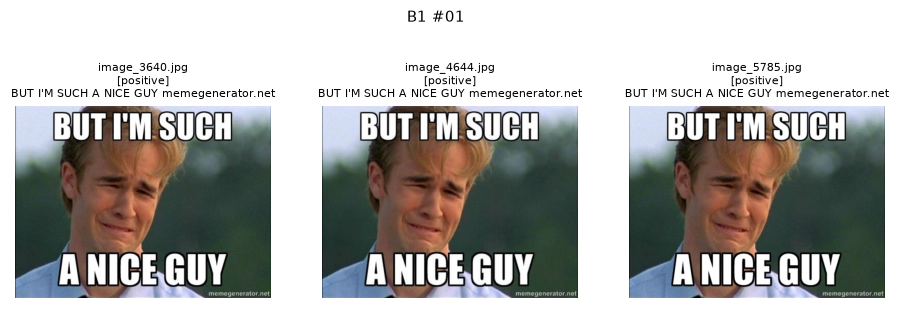

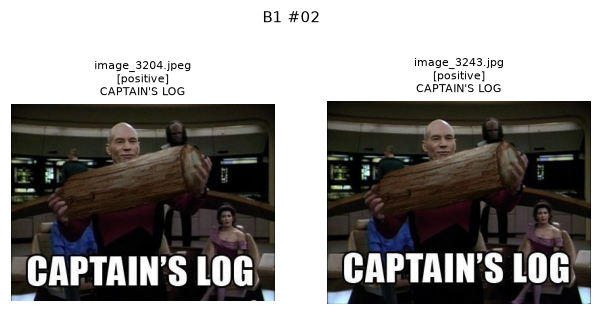

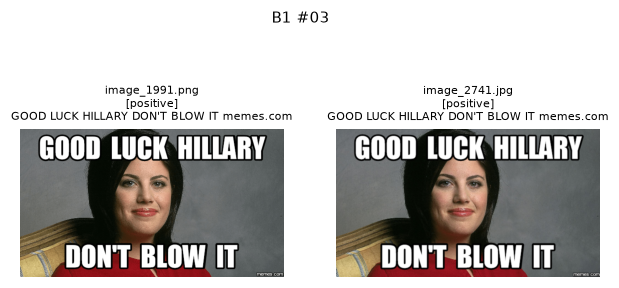

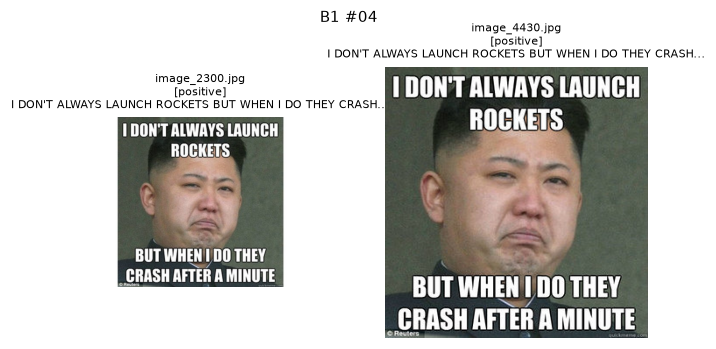

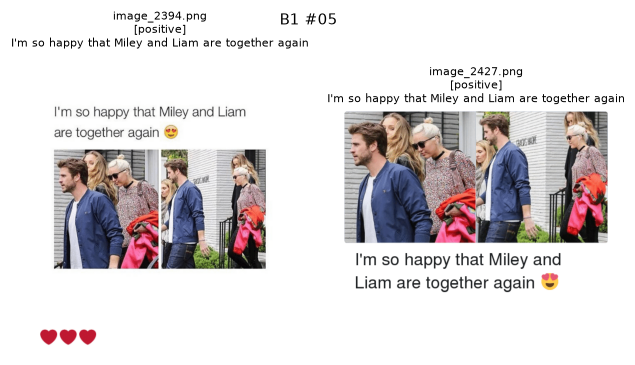

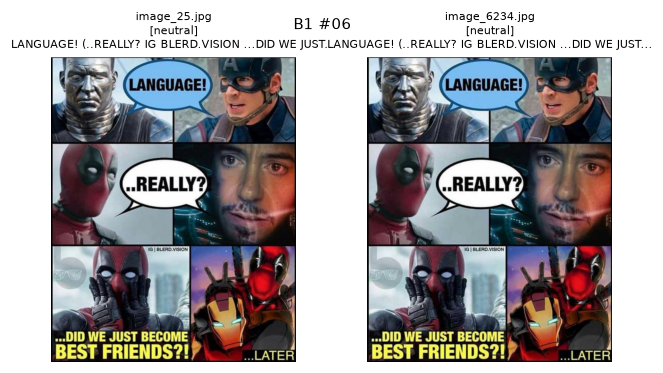

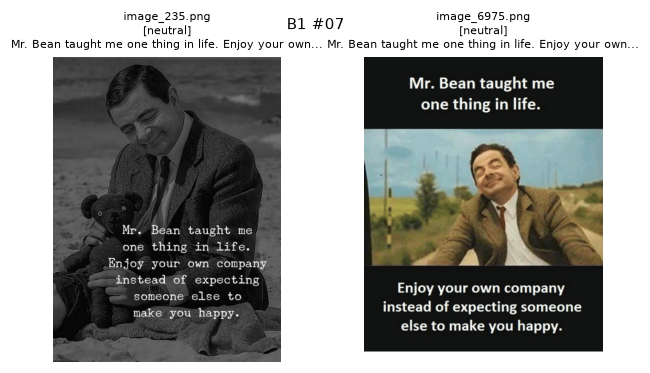

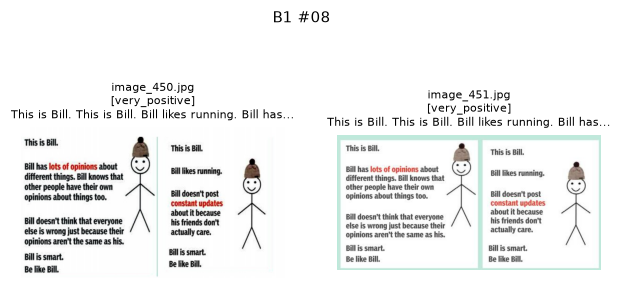

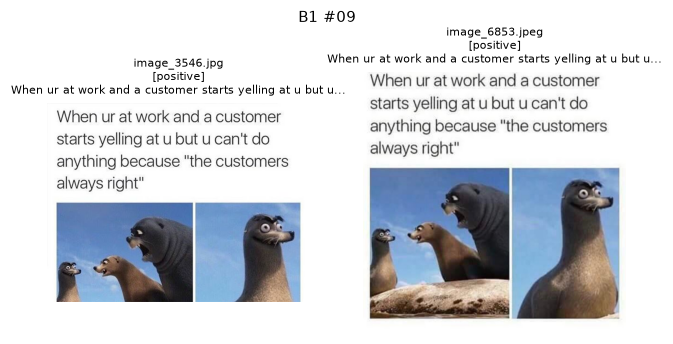

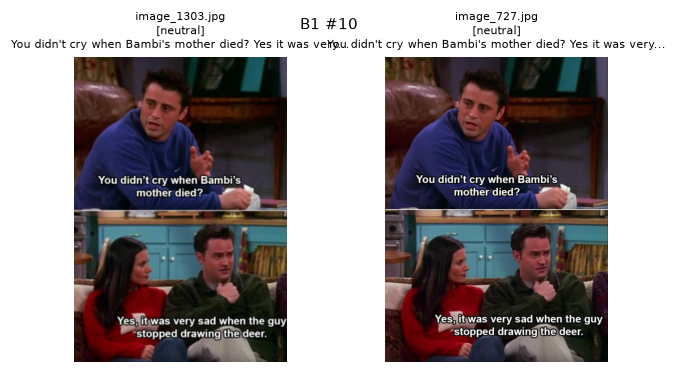

B1 10 images saved -> assets\eda\duplicates\B1


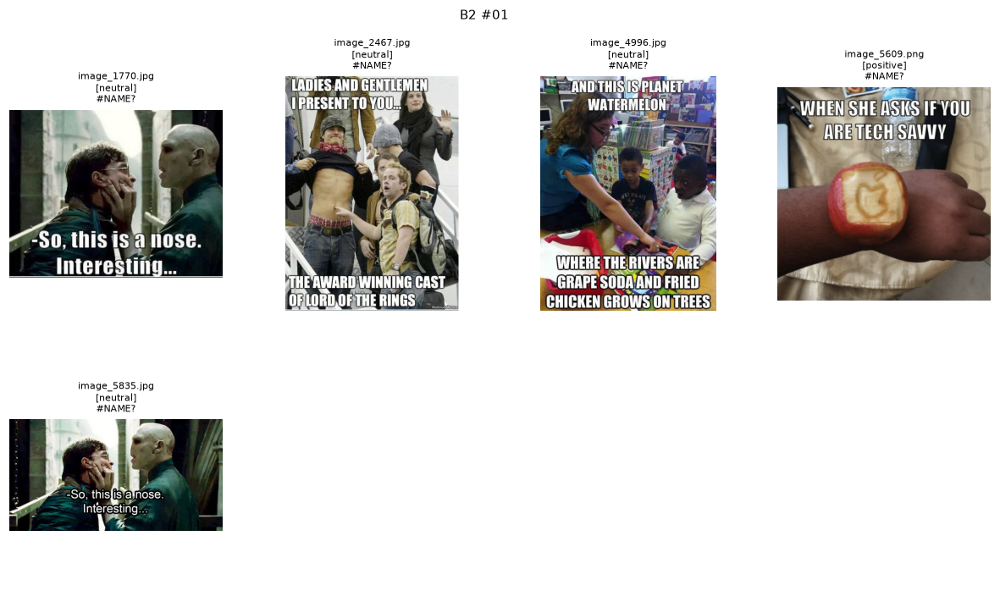

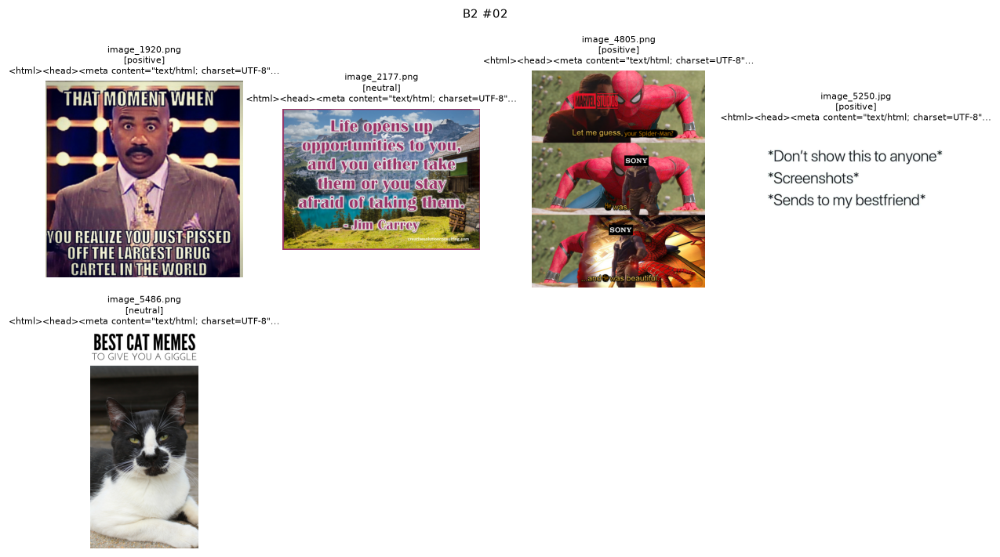

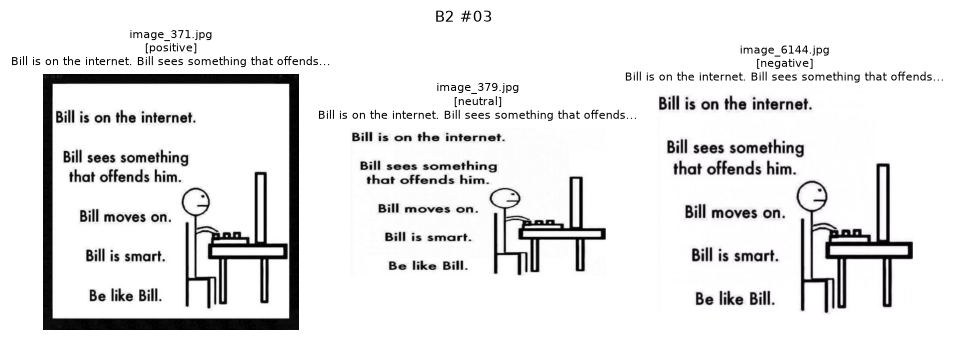

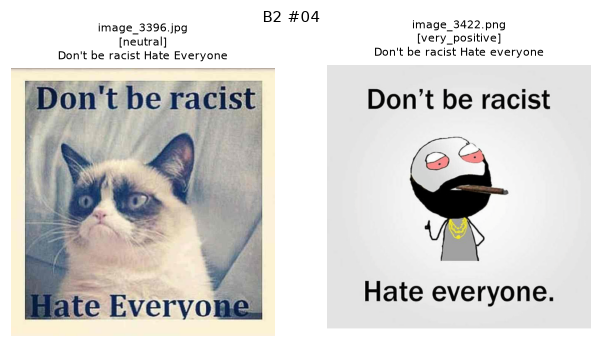

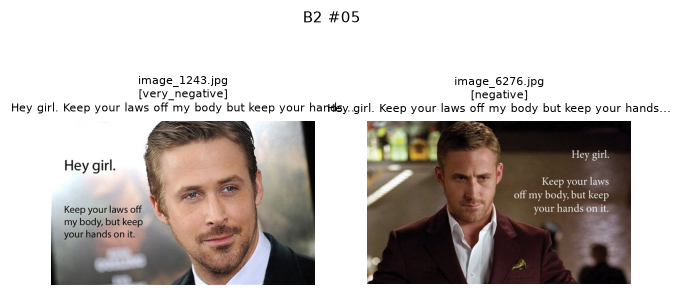

...

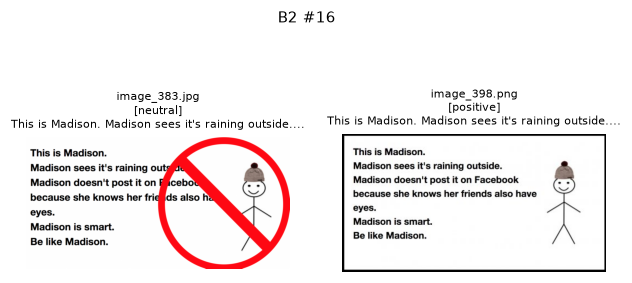

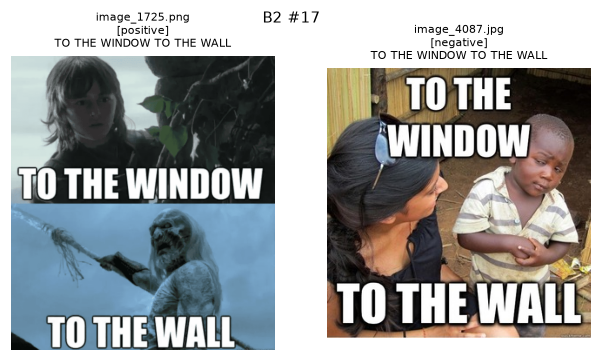

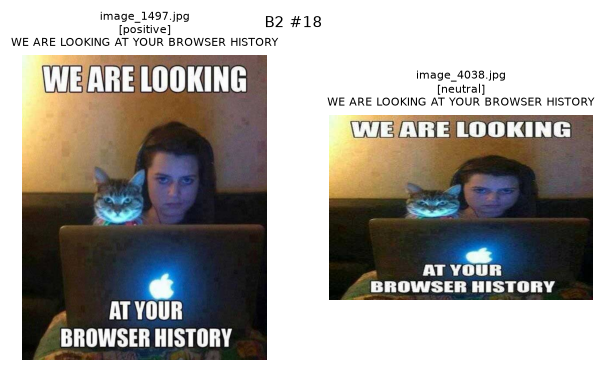

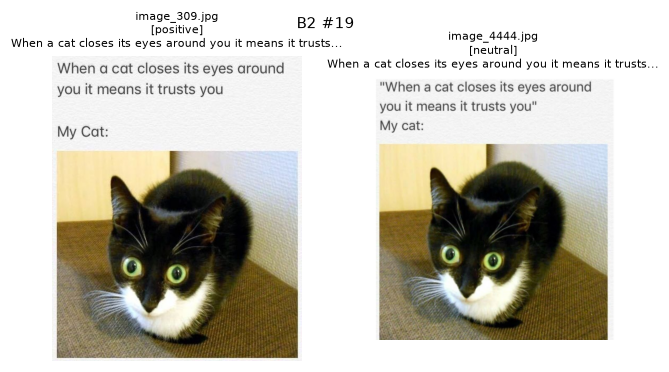

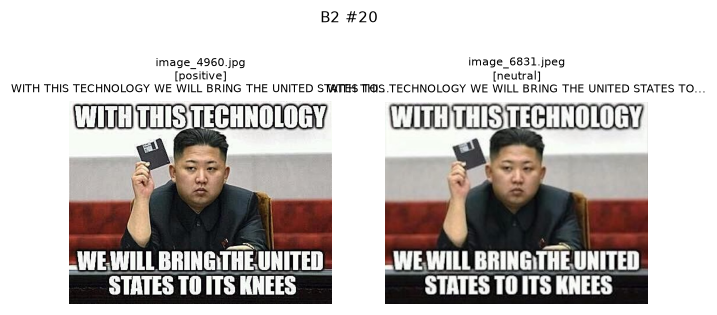

B2 20 images saved -> assets\eda\duplicates\B2


In [96]:
# Export every duplicate group as an image into assets/eda/duplicates/<category>/
import shutil
OUT = FIG_DIR / "duplicates"
if OUT.exists():
    shutil.rmtree(OUT)

def export_groups(code, groups, per_row=4):
    folder = OUT / code
    folder.mkdir(parents=True, exist_ok=True)
    for i, (k, g) in enumerate(groups, 1):
        g = g.sort_values("image_name")
        cols = min(len(g), per_row); rows = -(-len(g) // cols)
        fig, axes = plt.subplots(rows, cols, figsize=(3.4 * cols, 3.6 * rows), squeeze=False)
        for ax in axes.ravel():
            ax.axis("off")
        for ax, (_, r) in zip(axes.ravel(), g.iterrows()):
            ax.imshow(Image.open(IMAGE_ROOT / r["image_name"]).convert("RGB"))
            ax.set_title(f"{r['image_name']}\n[{r['label']}]\n" + textwrap.shorten(r["text_corrected"], 60, placeholder="..."),
                         fontsize=7)
        fig.suptitle(f"{code} #{i:02d}", fontsize=10)
        fig.savefig(folder / f"{code}_{i:02d}.png", bbox_inches="tight", dpi=100)
        plt.show()
    print(code, len(groups), "images saved ->", folder.relative_to(ROOT.parent))

for code, groups in dict(A1=A1, A2=A2, A3=A3, A4=A4, B1=B1, B2=B2).items():
    export_groups(code, groups)


### Junk images (HTML dumps, `#NAME?`, blank text, truncated image)

**Legend of junk types** (exported to `assets/eda/junk/<type>/`):

| Type | Meaning |
|---|---|
| `html_dump` | `text_corrected` is raw HTML code (`<html><head>...`) from a scraping error, not a caption |
| `name_error` | `text_corrected` is `#NAME?`, a spreadsheet formula error left in the data |
| `blank_text` | `text_corrected` is empty, so the pair has no text modality |
| `image_decode_failed` | The image file is truncated/corrupt and cannot be opened (only text and error are printed, no image) |

junk_type
blank_text             5
name_error             5
html_dump              5
image_decode_failed    1
blank_text: 5 image(s)

[image_120.jpg] label=positive | error=
''

[image_4800.jpg] label=neutral | error=
''

[image_6782.jpg] label=positive | error=
''

[image_6785.jpg] label=positive | error=
''

[image_6787.jpg] label=positive | error=
''


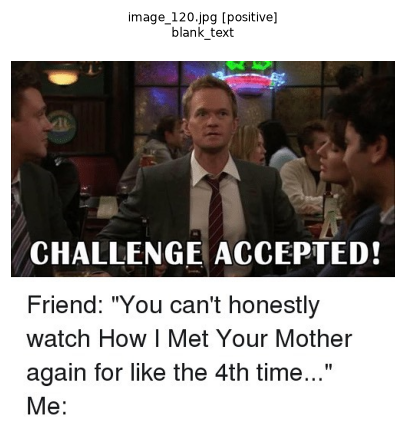

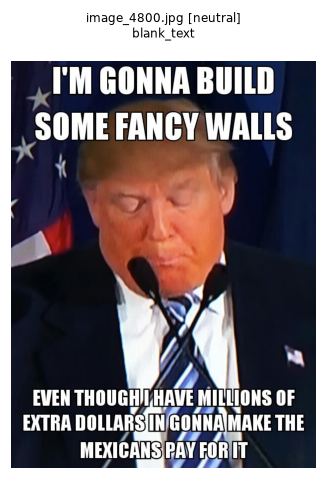

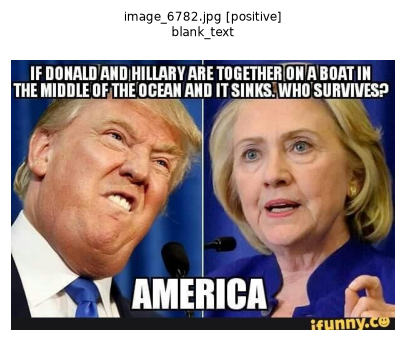

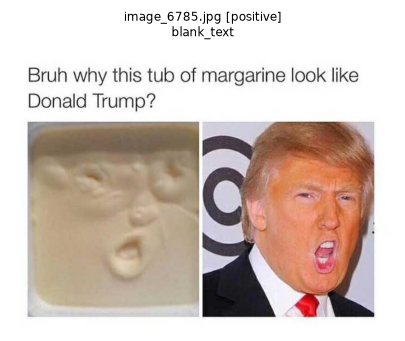

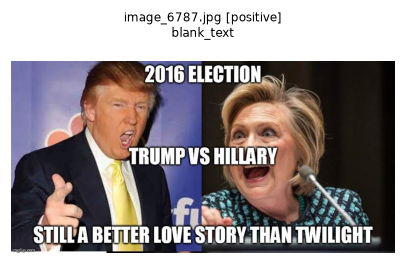

saved -> assets\eda\junk\blank_text
html_dump: 5 image(s)

[image_1920.png] label=positive | error=
'<html><head><meta content="text/html; charset=UTF-8" http-equiv="content-type"><style type="text/css">ol{margin:0;padding:0}table td'

[image_2177.png] label=neutral | error=
'<html><head><meta content="text/html; charset=UTF-8" http-equiv="content-type"><style type="text/css">ol{margin:0;padding:0}table td'

[image_4805.png] label=positive | error=
'<html><head><meta content="text/html; charset=UTF-8" http-equiv="content-type"><style type="text/css">ol{margin:0;padding:0}table td'

[image_5250.jpg] label=positive | error=
'<html><head><meta content="text/html; charset=UTF-8" http-equiv="content-type"><style type="text/css">ol{margin:0;padding:0}table td'

[image_5486.png] label=neutral | error=
'<html><head><meta content="text/html; charset=UTF-8" http-equiv="content-type"><style type="text/css">ol{margin:0;padding:0}table td'


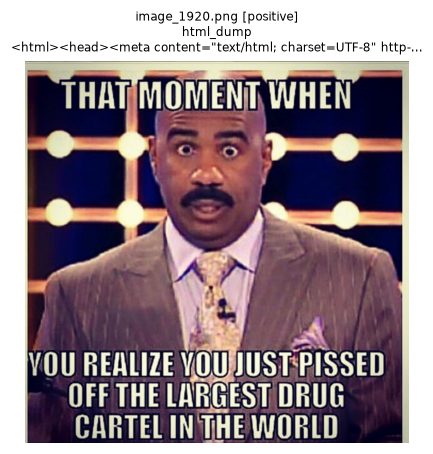

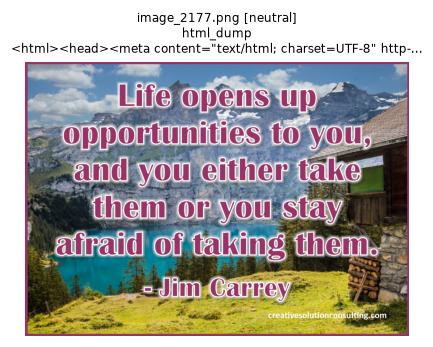

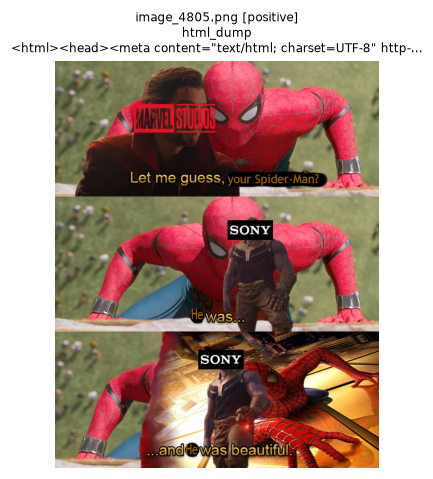

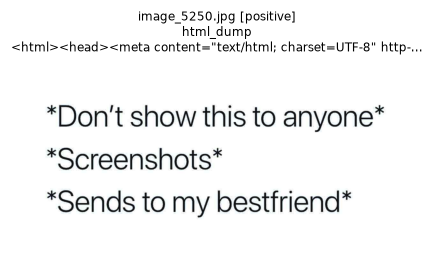

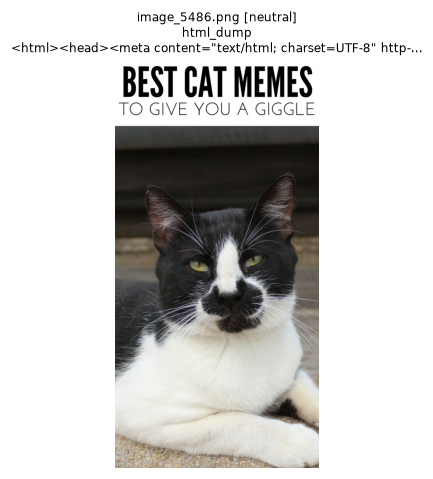

saved -> assets\eda\junk\html_dump
image_decode_failed: 1 image(s)

[image_5119.png] label=positive | error=OSError: image file is truncated
'When you\'re having a nice shift then someone says "wow it\'s been quiet" Nursingce Game of thrones'
cannot open image_5119.png -> image file is truncated
saved -> assets\eda\junk\image_decode_failed
name_error: 5 image(s)

[image_1770.jpg] label=neutral | error=
'#NAME?'

[image_2467.jpg] label=neutral | error=
'#NAME?'

[image_4996.jpg] label=neutral | error=
'#NAME?'

[image_5609.png] label=positive | error=
'#NAME?'

[image_5835.jpg] label=neutral | error=
'#NAME?'


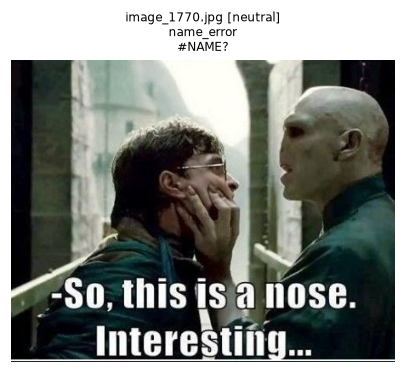

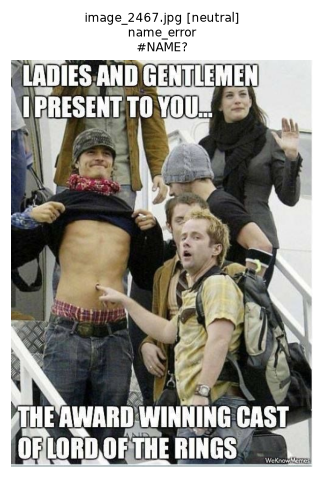

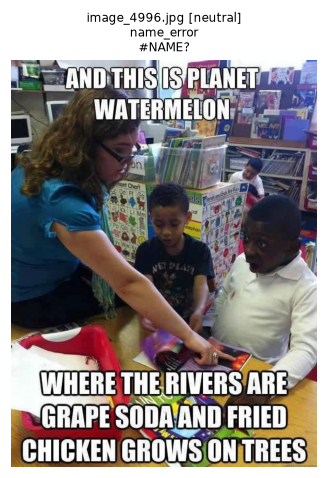

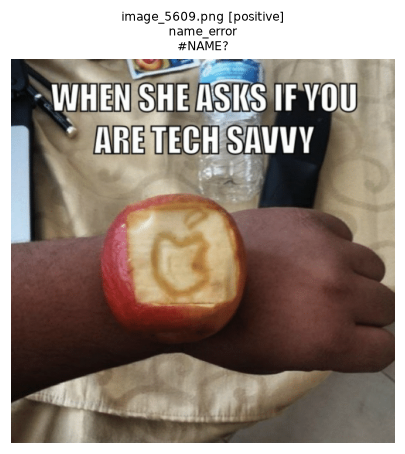

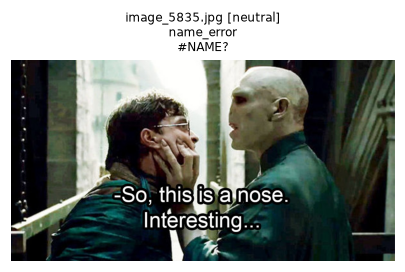

saved -> assets\eda\junk\name_error


In [97]:
# Junk / non-caption texts: print everything in full and export images to assets/eda/junk/
pd.set_option("display.max_colwidth", None)
J = df.copy()
t = J["text_corrected"].str.strip().str.lower()
J["junk_type"] = np.select(
    [t.str.contains(r"<html|<!doctype|<\?xml", regex=True), t.eq("#name?"), t.eq("")],
    ["html_dump", "name_error", "blank_text"], default="")
J.loc[(J["junk_type"] == "") & ~J["decode_ok"], "junk_type"] = "image_decode_failed"
J.loc[(J["junk_type"] == "") & t.str.match(r"^[^a-z0-9]*$"), "junk_type"] = "no_alphanumeric"
J = J[J["junk_type"] != ""]
print(J["junk_type"].value_counts().to_string())

JOUT = FIG_DIR / "junk"
if JOUT.exists():
    shutil.rmtree(JOUT)
for typ, g in J.groupby("junk_type"):
    print("=" * 100); print(f"{typ}: {len(g)} image(s)"); print("=" * 100)
    for _, r in g.iterrows():
        print(f"\n[{r['image_name']}] label={r['label']} | error={r['error']}\n{r['text_corrected']!r}")
    folder = JOUT / typ; folder.mkdir(parents=True, exist_ok=True)
    for _, r in g.iterrows():
        try:
            img = Image.open(IMAGE_ROOT / r["image_name"]).convert("RGB")
        except Exception as e:
            print("cannot open", r["image_name"], "->", e); continue
        fig, ax = plt.subplots(figsize=(4.5, 4.8))
        ax.imshow(img); ax.axis("off")
        ax.set_title(f"{r['image_name']} [{r['label']}]\n{typ}\n" + textwrap.shorten(r["text_corrected"], 70, placeholder="..."), fontsize=8)
        folder.mkdir(parents=True, exist_ok=True)
        fig.savefig(folder / f"{Path(r['image_name']).stem}.png", bbox_inches="tight", dpi=100)
        plt.show()
    print("saved ->", folder.relative_to(ROOT.parent))


## 7. Representative samples per class

saved assets\eda\assignment3-class-examples.png


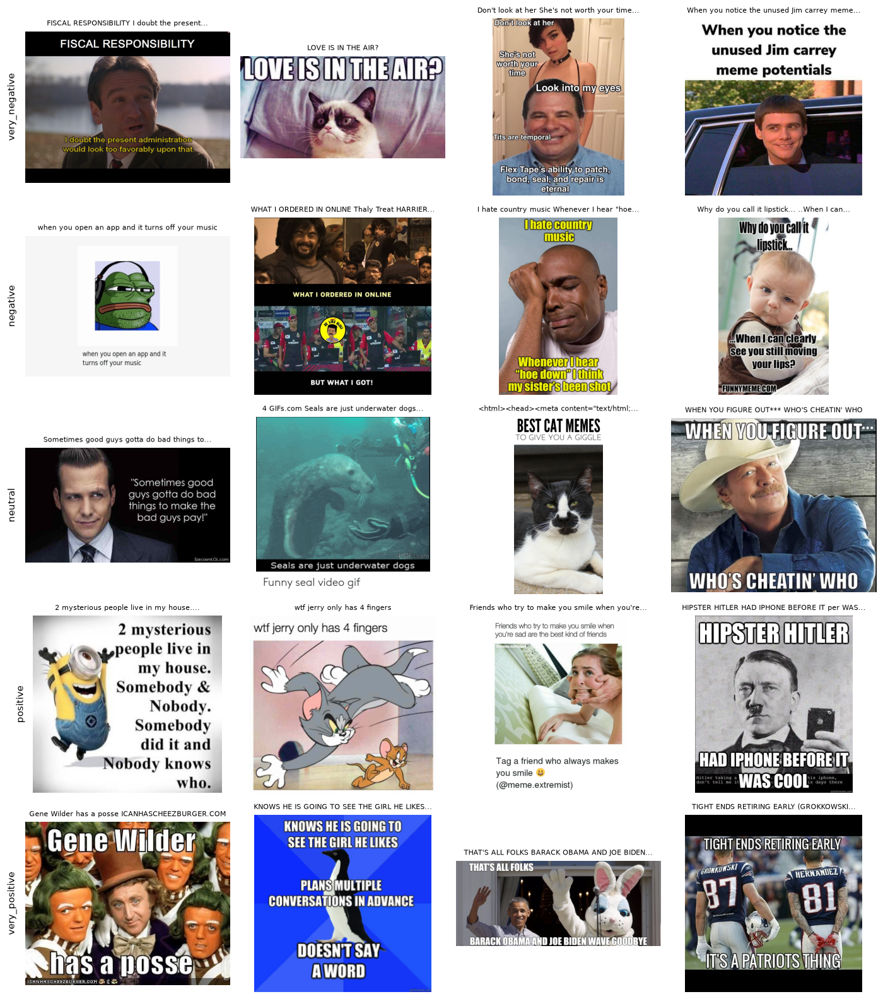

In [98]:
rng = np.random.default_rng(SEED)
elig = df[df["eligible"]]
per = 4
fig, axes = plt.subplots(len(LABELS), per, figsize=(3.2 * per, 2.9 * len(LABELS)))
for i, lab in enumerate(LABELS):
    pool = elig[elig["label"] == lab]
    pick = pool.iloc[rng.choice(len(pool), per, replace=False)]
    for j, (_, row) in enumerate(pick.iterrows()):
        ax = axes[i, j]
        ax.imshow(Image.open(IMAGE_ROOT / row["image_name"]).convert("RGB"))
        ax.set_title(textwrap.shorten(row["text_corrected"], 48, placeholder="..."), fontsize=7)
        ax.axis("off")
        if j == 0:
            ax.text(-0.04, 0.5, lab, transform=ax.transAxes, rotation=90, va="center", ha="right", fontsize=10)
plt.tight_layout(); savefig("class-examples"); plt.show()

## 8. Text content by class (word frequency)

In [99]:
import re
from collections import Counter
STOP = set("the a an and or of to in on at is are was were be it this that for with as by i you he she they we my your me "
           "so but not no do does did have has had from if when what who how can will just all".split())
def top_words(series, k=8):
    c = Counter(w for t in series for w in re.findall(r"[a-z']+", t.lower()) if w not in STOP and len(w) > 2)
    return [w for w, _ in c.most_common(k)]
display(pd.DataFrame({lab: top_words(elig.loc[elig["label"] == lab, "text_corrected"]) for lab in LABELS}))

,very_negative,negative,neutral,positive,very_positive
0,com,com,com,com,com
1,like,like,like,memes,bill
2,memes,i'm,imgflip,like,like
3,quickmeme,bill,memes,imgflip,memes
4,don't,memes,i'm,i'm,imgflip
5,people,imgflip,bill,bill,don't
6,you're,meme,don't,don't,quickmeme
7,i'm,don't,one,meme,i'm


## 9. Summary for the report

In [100]:
overall = {
    "raw_pairs": int(n),
    "eligible_pairs": int(df["eligible"].sum()),
    "excluded": int((~df["eligible"]).sum()),
    "classes": len(LABELS),
    "imbalance_ratio": round(float(cnt.max() / cnt.min()), 2),
    "majority_baseline": round(float(cnt.max() / n), 3),
    "median_words": float(ok["words"].median()),
    "p95_words": float(ok["words"].quantile(.95)),
    "dup_image_groups": int(dup_img["pixel_sha256"].nunique()),
    "dup_text_groups": int(dup_txt["text_norm"].nunique()),
    "junk_texts": int(junk.sum()),
    "images_in_candidate_groups": int(len(affected)),
}
pd.Series(overall).to_frame("value")

,value
raw_pairs,6992.000
eligible_pairs,6986.000
excluded,6.000
classes,5.000
imbalance_ratio,20.710
majority_baseline,0.447
median_words,13.000
p95_words,31.000
dup_image_groups,25.000
dup_text_groups,46.000


## 10. After cleaning and splitting (final data used for training)

Sections 1-9 describe the **raw** release. Here we describe what the models actually see:
`data/clean/cleaned.csv` (output of `scripts/clean_dataset.py`) and the frozen group-aware
70/15/15 manifests in `data/manifests/` (`scripts/prepare_splits.py`, seed 42).


In [101]:
clean = pd.read_csv(ROOT / "data/clean/cleaned.csv", encoding="utf-8-sig", keep_default_na=False)
removed = pd.read_csv(ROOT / "data/clean/removed.csv", encoding="utf-8-sig", keep_default_na=False)
print(f"raw {len(df):,} -> cleaned {len(clean):,} (removed {len(removed)})\n")
steps = removed.groupby("step", sort=False).agg(removed=("image_name", "size"), reason=("reason", "first"))
display(steps)
print("every remaining image is its own group (max group size):", clean.groupby("group_id").size().max())


raw 6,992 -> cleaned 6,887 (removed 105)



,removed,reason
step,,
Image cannot be fully decoded,1,image file is truncated/corrupt and cannot be decoded
Blank text_corrected,5,"no text, so the image-text pair is incomplete"
"Junk text (#NAME?, <html>, no alphanumerics)",10,text is not a caption (#NAME? / HTML dump / no alphanumerics)
Equivalent pairs with conflicting labels (drop all),21,identical image+text with different labels: label cannot be trusted (A3)
"Equivalent pairs, same label (keep 1 copy)",6,"identical image+text+label: redundant copy, keep 1 (A1)"
"Same image, conflicting labels (drop all)",12,same image with different labels (text differs slightly): label noise (A4)
"Same image, same label, text differs slightly (keep 1 copy)",3,"same image+label, only OCR/typo differences in text, redundant copy (A2)"
"Same text, near-identical image, conflicting labels (drop all)",10,re-encoded/resized copy of the same meme with different labels: label noise (B2)
"Same text, near-identical image, same label (keep 1 copy)",4,"re-encoded/resized copy of the same meme, same label: redundant copy (B1)"


every remaining image is its own group (max group size): 1


C:\Users\huytr\AppData\Local\Temp\ipykernel_20948\4195110880.py:6: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  display(tab.join(pct, rsuffix=" %"))


,train,val,test,all,train %,val %,test %,all %
label_id,,,,,,,,
very_negative,102,22,23,147,2.1,2.1,2.2,2.1
negative,333,71,71,475,6.9,6.9,6.9,6.9
neutral,1519,326,325,2170,31.5,31.5,31.4,31.5
positive,2155,462,462,3079,44.7,44.7,44.7,44.7
very_positive,710,153,153,1016,14.7,14.8,14.8,14.8


split sizes: {'train': 4819, 'val': 1034, 'test': 1034}
saved assets\eda\assignment3-split-class-distribution.png


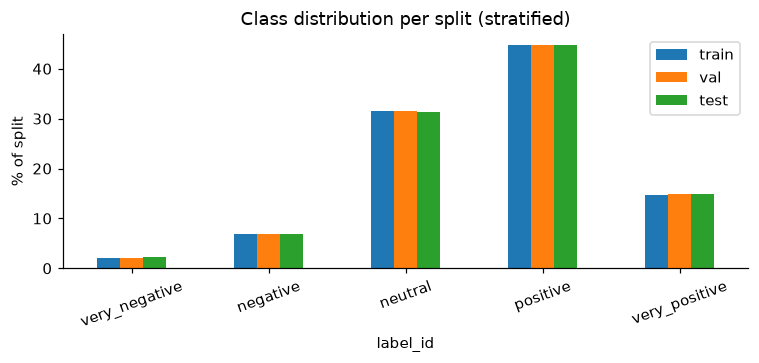

In [102]:
M = {s: pd.read_csv(ROOT / f"data/manifests/{s}.csv", keep_default_na=False) for s in ("train", "val", "test")}
inv = {0: "very_negative", 1: "negative", 2: "neutral", 3: "positive", 4: "very_positive"}
tab = pd.DataFrame({s: m["label_id"].map(inv).value_counts().reindex(LABELS) for s, m in M.items()})
tab["all"] = tab.sum(axis=1)
pct = (tab / tab.sum() * 100).round(1)
display(tab.join(pct, rsuffix=" %"))
print("split sizes:", {s: len(m) for s, m in M.items()})

fig, ax = plt.subplots(figsize=(7, 3.4))
(pct[["train", "val", "test"]]).plot.bar(ax=ax)
ax.set_ylabel("% of split"); ax.set_title("Class distribution per split (stratified)")
plt.xticks(rotation=20); plt.tight_layout(); savefig("split-class-distribution"); plt.show()


In [103]:
rows = []
for s, m in M.items():
    w = m["text_corrected"].str.split().str.len()
    rows.append({"split": s, "n": len(m), "median words": w.median(), "p95 words": w.quantile(.95),
                 "max words": w.max(), "> 64 words": int((w > 64).sum())})
display(pd.DataFrame(rows).set_index("split"))

import json
vocab = json.loads((ROOT / "data/processed/vocabulary.json").read_text(encoding="utf-8"))["token_to_id"]
import sys; sys.path.insert(0, str(ROOT))
from src.data.tokenizer import tokenize
for s in ("val", "test"):
    toks = [t for x in M[s]["text_corrected"] for t in tokenize(x)]
    print(f"{s}: unknown-token rate {sum(t not in vocab for t in toks) / len(toks):.1%}")
print("vocabulary size (train only, min_freq=2):", len(vocab))


,n,median words,p95 words,max words,> 64 words
split,,,,,
train,4819,13.0,30.00,96,6
val,1034,13.0,32.35,189,3
test,1034,13.0,32.00,94,2


val: unknown-token rate 13.8%
test: unknown-token rate 12.2%
vocabulary size (train only, min_freq=2): 4295


In [104]:
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert not set(M[a]["group_id"]) & set(M[b]["group_id"]), (a, b)
    assert not set(M[a]["image_name"]) & set(M[b]["image_name"]), (a, b)
assert all(m["label_id"].nunique() == 5 for m in M.values())
print("OK: no group/image overlap between splits; all 5 classes present in every split")
print(json.dumps({s: v["sha256"][:16] + "..." for s, v in json.loads((ROOT / "data/manifests/split_report.json").read_text())["splits"].items()}, indent=1))


OK: no group/image overlap between splits; all 5 classes present in every split
{
 "train": "bf2ac66013668ced...",
 "val": "31296fb8c194c7a9...",
 "test": "dce34d79d6f3d5ff..."
}


## 11. Findings and limitations

- **Pair validity:** pairs come from one Memotion-derived Kaggle release, so image and text belong to the same meme. Text is the OCR/corrected caption embedded in the image, so text and image are strongly redundant.
- **Cleaning (raw 6,992 -> 6,887 pairs, 105 removed = 1.5%):** 1 undecodable image, 5 blank texts, 10 junk texts (`#NAME?`, HTML dumps), and 89 duplicate-related removals. Rules and counts per step are in `data/clean/removed.csv` and Section 10. Raw files are never modified.
- **Duplicates and label noise:** in the raw data 16 of 25 duplicate-image groups and 20 of 30 repeated-caption groups carry conflicting labels, i.e. the same input gets different sentiment. Policy: identical or near-identical pairs with conflicting labels are dropped entirely; same-label copies keep one. After cleaning every image is its own group, so the group-aware split is also safe against template/duplicate leakage.
- **Class balance (cleaned):** strongly imbalanced - very_negative 147 (2.1%), negative 475 (6.9%), neutral 2,170 (31.5%), positive 3,079 (44.7%), very_positive 1,016 (14.8%). Imbalance ratio about 20.9; majority-class baseline 44.7%. Report macro-F1 alongside accuracy and use class weights instead of oversampling.
- **Split:** random, label-stratified, group-aware 70/15/15 with seed 42 -> train 4,819 / val 1,034 / test 1,034; all 5 classes in every split (very_negative has only 22-23 samples in val/test, so per-class metrics there are noisy).
- **Text:** median 13 words, p95 about 31; 11 texts exceed 64 words and are truncated to `max_text_length = 64`. Vocabulary is built from train only (4,295 tokens); about 12-14% of val/test tokens are unknown. OCR and corrected text differ often (only 67.9% identical in raw data), so `text_corrected` is used. Frequent tokens like `com`, `imgflip`, `memegenerator` are watermarks, not sentiment cues.
- **Images:** resized to 224 with aspect ratio preserved and padded; ImageNet mean/std; light brightness/contrast jitter on train only (no horizontal flip because text is inside the image).
- **Limitations:** subjective sentiment labels with visible conflicts on identical inputs (label noise caps achievable accuracy), meme-template reuse, possible source-license/usage constraints, text partly redundant with image pixels, and very few very_negative samples.
